In [2]:
# Cat vs. dog classification

# steps
# Step 1: Load and Preprocess Dog Images
    # 1. Initialize containers
    # 2. Loop through 500 images:
    # 3. Convert to RGB:
    # 4. Resize to 64×64:
    # 5. Convert to a NumPy array:
    # 6. Append to the list:
# Step 2: Load and Preprocess Cat Images
    # 1. Initialize containers
    # 2. Loop through 500 images:
    # 3. Convert to RGB:
    # 4. Resize to 64×64:
    # 5. Convert to a NumPy array:
    # 6. Append to the list:
# Step 3: Combine Dogs and Cats into One Dataset
    # 1. Concatenate the image lists: dog_array + cat_array
    # 2. Convert to a NumPy array: np.array(...)
    # 3. Build the label array: dog_output + cat_output
    # 4. Reshape: X.reshape(-1, 64, 64, 3)
    # 5. Print the shapes:
# Step 4: Build the CNN Model
    # 1. Feature extraction (Conv + Pool blocks):
    # 2. Flatten: 
    # 3. Classification (Dense layers):
    # 4. Softmax output:
# Step 5: Compile the Model
# Step 6: Train the Model

In [20]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as pl
from tensorflow import keras
from sklearn.model_selection import train_test_split

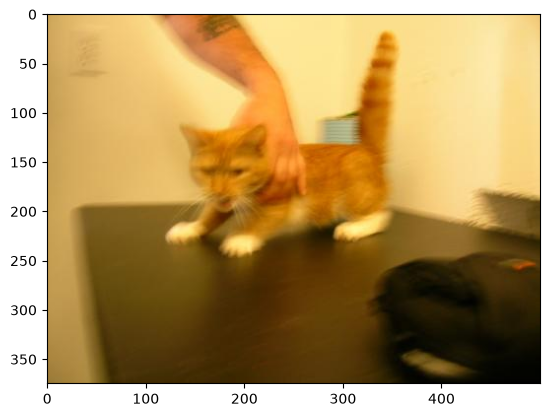

(375, 500, 3)

In [3]:
img = Image.open("PetImages/Cat/0.jpg")
pl.imshow(img)
pl.show()
np.shape(img)

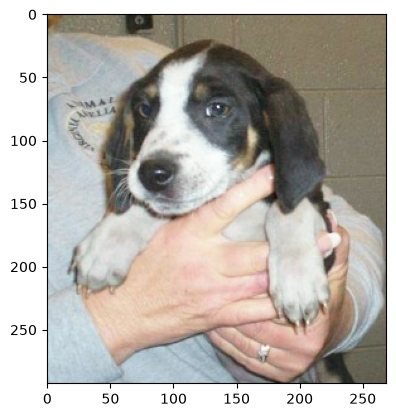

In [4]:
img = Image.open("PetImages/Dog/10.jpg")
pl.imshow(img)
pl.show()

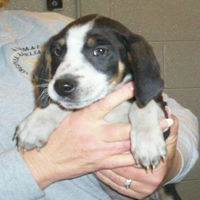

In [5]:
img_resized = img.resize((200,200))
img_resized

In [6]:
# Step 1: Load and Preprocess Dog Images

dog_array = []
dog_output = [0]*500
for i in range(500):
    img = Image.open(f"PetImages/Dog/{i}.jpg").convert('RGB')
    img = img.resize((64,64))
    arr = np.array(img)
    dog_array.append(arr)

# Step 2: Load and Preprocess Cat Images

cat_array = []
cat_output = [1]*500
for i in range(500):
    img = Image.open(f"PetImages/Cat/{i}.jpg").convert('RGB')
    img = img.resize((64,64))
    arr = np.array(img)
    cat_array.append(arr)

# Step 3: Combine Dogs and Cats into One Dataset

X = np.array(dog_array + cat_array)
y = np.array(dog_output + cat_output)
X = X.reshape(-1,64,64,3)
print(X.shape, y.shape)

(1000, 64, 64, 3) (1000,)


In [7]:
# Step 4: Build the CNN Model

model = keras.Sequential([
    keras.layers.Input((64,64,3)),

    # Extract visual features
    keras.layers.Conv2D(16,kernel_size=(3,3), activation="relu"),
    keras.layers.MaxPool2D(pool_size=(2,2)),

    keras.layers.Conv2D(8,kernel_size=(3,3), activation="relu"),
    keras.layers.MaxPool2D(pool_size=(2,2)),

    # Convert features into a vector
    keras.layers.Flatten(),

    # Learn classification patterns
    keras.layers.Dense(32,activation='relu'), # input layer
    
    keras.layers.Dense(16,activation='relu'), # hidden layer
    keras.layers.Dense(8,activation='relu'), # hidden layer
    
    keras.layers.Dense(2,activation='softmax'), # output layer
    
])

In [8]:
# Step 5: Compile the Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
# Step 6: Train the Model
model.fit(X,y,epochs=10)

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5030 - loss: 2.7125
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5660 - loss: 0.7792
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6290 - loss: 0.6645
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.6510 - loss: 0.6028
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6940 - loss: 0.5518
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7090 - loss: 0.5466
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7540 - loss: 0.4811
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7820 - loss: 0.4409
Epoch 9/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8100 - loss: 0.4037
Epoch 10/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8520 - loss: 0.3402


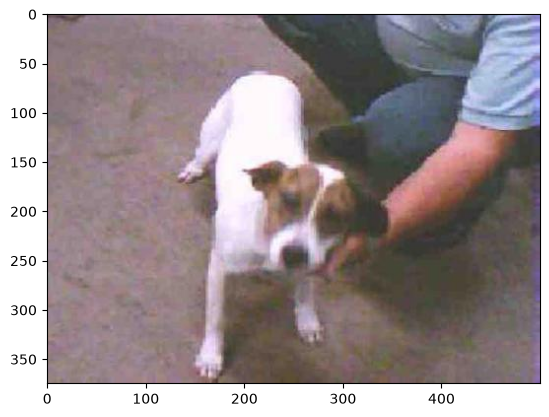

In [10]:
# test image
test_image = Image.open("PetImages/Dog/1233.jpg")
pl.imshow(test_image)

In [15]:
import os

In [16]:
def load_folder(folder, label):
    images, labels = [], []
    for fname in os.listdir(folder):
        try:
            with Image.open(f'{folder}/{fname}') as img:
                arr = np.array(img.convert('RGB').resize((64, 64)))
                images.append(arr)
                labels.append(label)
        except Exception as e:
            print('skipped', fname, type(e).__name__)
    return images, labels
 
dog_array, dog_output = load_folder('PetImages/Dog', 0)
cat_array, cat_output = load_folder('PetImages/Cat', 1)
 
X = np.array(dog_array + cat_array)
y = np.array(dog_output + cat_output)
print(X.shape, y.shape)

C:\Users\Hemraj\AppData\Local\Programs\Python\Python314\Lib\site-packages\PIL\TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


(24998, 64, 64, 3) (24998,)


In [18]:
len(os.listdir('PetImages/Cat/'))

12499

In [19]:
y

array([0, 0, 0, ..., 1, 1, 1], shape=(24998,))

In [21]:
X_TRAIN,X_TEST,y_train,y_test = train_test_split(X, y)

In [22]:
import pandas as pd

pd.Series(y_train).value_counts()

1    9434
0    9314
Name: count, dtype: int64

In [23]:
model = keras.Sequential([
    keras.layers.Input((64,64,3)),
 
    keras.layers.Conv2D(16,kernel_size=(3,3),activation='relu'),
    keras.layers.MaxPool2D(pool_size=(2,2)),
 
    keras.layers.Conv2D(8,kernel_size=(3,3),activation='relu'),
    keras.layers.MaxPool2D(pool_size=(2,2)),
 
    keras.layers.Flatten(),
 
    keras.layers.Dense(32,activation='relu'), # < input layer
    keras.layers.Dropout(0.1),
    keras.layers.Dense(16,activation='relu'), # <- hidden layer
    keras.layers.Dropout(0.1),
    keras.layers.Dense(8,activation='relu'), # <- hidden layer
    keras.layers.Dropout(0.1),
 
    keras.layers.Dense(2,activation='softmax'), # <- output layer
])
 
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])
 
model.fit(X_TRAIN,y_train,epochs=20)

Epoch 1/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.5069 - loss: 0.8978
Epoch 2/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5199 - loss: 0.6900
Epoch 3/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5323 - loss: 0.6865
Epoch 4/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5349 - loss: 0.6832
Epoch 5/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5408 - loss: 0.6820
Epoch 6/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5530 - loss: 0.6788
Epoch 7/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.5558 - loss: 0.6758
Epoch 8/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.5589 - loss: 0.6705
Epoch 9/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.5622 - loss: 0.6708
Epoch 10/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.5747 - loss: 0.6631
Epoch 11/20
586/586 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5782 - loss: 0.6575
Epoch 12/20
586/586 ━━━━━━━━━━━━━━━━━━━